In [1]:
# First step import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
print("Lets Goooo!")

Lets Goooo!


In [2]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# A box will appear at the top of VS Code asking for your password. Type it and press Enter.
password = getpass("PostgreSQL password: ")

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="yelp_project",
)
engine = create_engine(url)

# Ask the database one simple question to prove the connection works
with engine.connect() as conn:
    rows = conn.execute(text("SELECT COUNT(*) FROM clean.reviews")).scalar()
print("Connected. Reviews in clean.reviews:", rows)

Connected. Reviews in clean.reviews: 307510


In [3]:
import sys
print(sys.executable)

C:\Users\DELL PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


In [4]:
# CHECKING THE CONNECTION AND IMPORTING LIBRARIES


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# --- connect to the database (the password is never saved in the file) ---
password = getpass("PostgreSQL password: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=password,
    host="localhost", port=5432, database="yelp_project"))

# --- load the four clean tables (the reviews table takes 10-30 seconds) ---
business   = pd.read_sql("SELECT * FROM clean.business", engine)
users      = pd.read_sql("SELECT * FROM clean.users", engine)
reviews    = pd.read_sql("SELECT * FROM clean.reviews", engine)
categories = pd.read_sql("SELECT * FROM clean.business_categories", engine)

# --- check the shapes: (rows, columns) ---
print("business  ", business.shape)
print("users     ", users.shape)
print("reviews   ", reviews.shape)
print("categories", categories.shape)

business   (52263, 13)
users      (214971, 8)
reviews    (307510, 17)
categories (243587, 2)


In [5]:
# What we’re doing: before making any chart, check the column types, count the missing values,
#  and read the summary numbers. This is the Python version of the profiling you did in SQL, 
# and it also confirms nothing changed on the way in.


# --- 1) column names and types of the reviews table
print(reviews.dtypes)

# --- 2) missing values, as COUNTS (a percentage would round tiny numbers to 0)
for name, df in [("business", business), ("users", users), ("reviews", reviews) , ("categories", categories)]:
    miss = df.isna().sum()
    print(f"{name}: missing ->", miss[miss > 0].to_dict() or "none")

# --- 3) summary of the number columns
print(reviews[["stars", "text_length", "useful_votes"]].describe().round(2))
print(business[["business_stars", "total_reviews_all_time"]].describe().round(2))


review_id                  object
user_id                    object
business_id                object
stars                       int64
star_group                 object
review_datetime    datetime64[ns]
review_date                object
review_year                 int64
review_month                int64
is_partial_year             int64
useful_votes                int64
funny_votes                 int64
cool_votes                  int64
review_text                object
text_length                 int64
is_short_review             int64
has_url                     int64
dtype: object
business: missing -> {'postal_code': 21}
users: missing -> {'total_reviews_all_time': 2}
reviews: missing -> none
categories: missing -> none
           stars  text_length  useful_votes
count  307510.00    307510.00     307510.00
mean        3.79       544.41          0.98
std         1.39       502.66          2.58
min         1.00         1.00          0.00
25%         3.00       218.00          0.00
50

stars
1    12.0
2     8.6
3    11.5
4    23.9
5    44.0
Name: proportion, dtype: float64


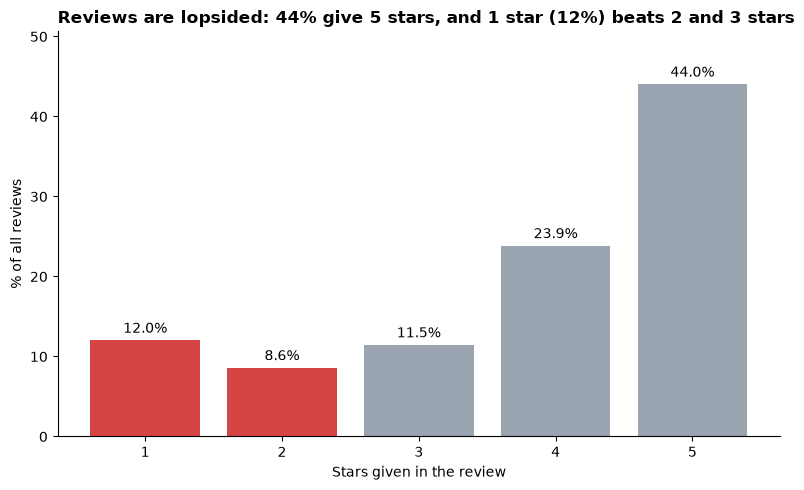

negative share (1-2 stars): 20.6 %


In [ ]:
# What we’re doing: 
# before comparing states or years, we need to know what a normal review looks like. 
# This is the baseline everything else gets measured against.

# THIS TABLE SHOWS THE PERCENTAGE OF REVIEWS THAT GIVE EACH STAR RATING, 
# AND IT ALSO SHOWS THE PERCENTAGE OF REVIEWS THAT ARE NEGATIVE (1 OR 2 STARS).


# 1) what share of all reviews gives each star rating?
share = reviews["stars"].value_counts(normalize=True).sort_index() * 100
print(share.round(1))

# 2) draw it: red = negative (1-2 stars), grey = everything else
colors = ["#D64545" if s <= 2 else "#9AA5B1" for s in share.index]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(share.index, share.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Stars given in the review")
ax.set_ylabel("% of all reviews")
ax.set_title(f"Reviews are lopsided: {share[5]:.0f}% give 5 stars, and 1 star ({share[1]:.0f}%) beats 2 and 3 stars",
             loc="left", fontsize=12, fontweight="bold")
ax.set_ylim(0, share.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

print("negative share (1-2 stars):", round(share[[1, 2]].sum(), 1), "%")

rows before the join: 307510 | after: 307510
       reviews  pct_negative
state                       
IL        2362          27.3
DE        3228          25.4
NJ       11110          24.7
NV       15888          22.9
AZ       17110          22.8
AB        4531          21.5
ID        6756          21.0
FL       51398          20.8
PA       71967          20.7
MO       23100          20.7
TN       28229          20.3
IN       21952          19.7
LA       36180          18.2
CA       13699          17.3

baseline (all reviews): 20.6% negative


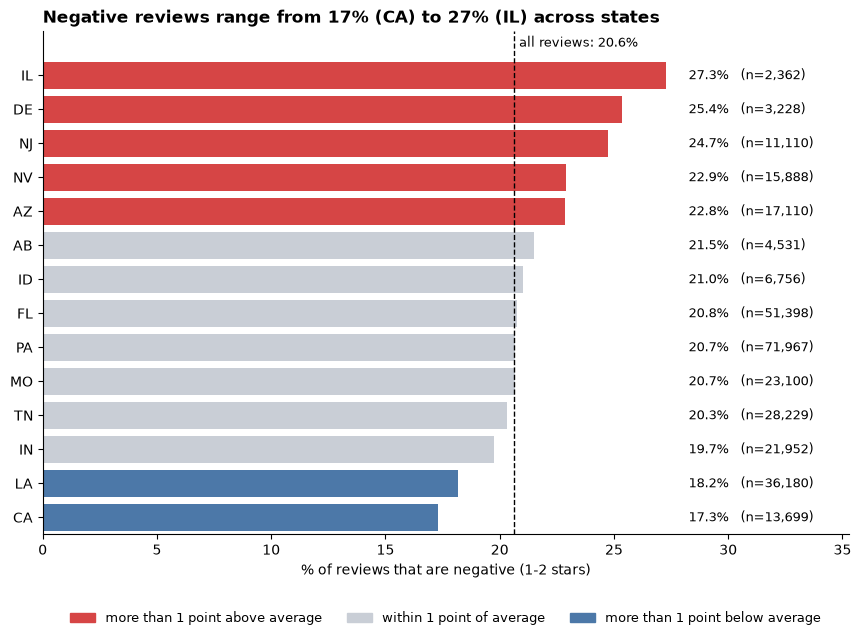

In [7]:
# WHICH STATES HAVE THE MOST NEGATIVE/UNHAPPY REVIEWS? (1 OR 2 STARS)

from matplotlib.patches import Patch

# 1) attach each review's state (a join). The row counts before and after must match.
before = len(reviews)
rev = reviews.merge(business[["business_id", "state", "country"]], on="business_id", how="left")
print("rows before the join:", before, "| after:", len(rev))

# 2) for each state: how many reviews, and what % of them are negative (1-2 stars)?
rev["is_negative"] = (rev["star_group"] == "negative")
by_state = (rev.groupby("state")
               .agg(reviews=("review_id", "count"), pct_negative=("is_negative", "mean"))
               .assign(pct_negative=lambda d: d["pct_negative"] * 100)
               .sort_values("pct_negative", ascending=False))
baseline = rev["is_negative"].mean() * 100
print(by_state.round(1))
print(f"\nbaseline (all reviews): {baseline:.1f}% negative")

# 3) draw it. Colour only the states that are clearly different from the baseline (more than 1 point away)
def pick_color(p):
    if p > baseline + 1: return "#D64545"      # clearly worse than average
    if p < baseline - 1: return "#4C78A8"      # clearly better than average
    return "#C9CED6"                           # about the same as average
colors = [pick_color(p) for p in by_state["pct_negative"]]

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(by_state.index, by_state["pct_negative"], color=colors)
ax.invert_yaxis()                                   # highest at the top
ax.axvline(baseline, color="black", linestyle="--", linewidth=1)
ax.text(baseline + 0.2, -0.75, f"all reviews: {baseline:.1f}%", fontsize=9, va="bottom")
label_x = by_state["pct_negative"].max() + 1.0       # labels sit in one column on the right
for bar, n in zip(bars, by_state["reviews"]):
    ax.text(label_x, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%   (n={n:,})", va="center", fontsize=9)
ax.set_xlabel("% of reviews that are negative (1-2 stars)")
ax.set_xlim(0, label_x + 7)
ax.set_ylim(len(by_state) - 0.5, -1.3)
top, low = by_state.index[0], by_state.index[-1]
ax.set_title(f"Negative reviews range from {by_state['pct_negative'].min():.0f}% ({low}) to {by_state['pct_negative'].max():.0f}% ({top}) across states",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#D64545", label="more than 1 point above average"),
                   Patch(color="#C9CED6", label="within 1 point of average"),
                   Patch(color="#4C78A8", label="more than 1 point below average")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

HOW TO READ THE CHART -

The bars are states ... the lenght shows the percentage of how bad the reviews are (1 or 2 stars)

The dashed line shows the share of ALL reviews that are negative (1 to 2 stars): 20.6%, or about 1 in 5.
Each bar shows the same share for one state. A bar that reaches past the line means that state
has a higher share of negative reviews than the overall average. A shorter bar means a lower share.
Red marks states clearly above average, and blue marks states clearly below.

n - number of reveiws the state has